In [1]:
import cartopy.crs as ccrs
import numpy as np
import xarray as xr
import pyremo as pr
import cmaps
import glob
from REMO2020_mod import modelclass, prepare_hcorrection, season_mean, eobs_temp_open, open_mfdataset, domainclass, plotclass, remo_plotter

ERROR 1: PROJ: proj_create_from_database: Open of /work/ch0636/g300096/Python/envs/kernelR2020/share/proj failed


In [2]:
from dask.distributed import Client, progress
import dask
dask.config.set({'temporary_directory': '/scratch/g/g300096/dask/tmp'})
client = Client()
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /user/g300096/levante-spawner-preset//proxy/8787/status,
Dashboard: /user/g300096/levante-spawner-preset//proxy/8787/status,Workers: 16
Total threads: 256,Total memory: 235.37 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:40113,Workers: 16
Dashboard: /user/g300096/levante-spawner-preset//proxy/8787/status,Total threads: 256
Started: Just now,Total memory: 235.37 GiB
Comm: tcp://127.0.0.1:43251,Total threads: 16
Dashboard: /user/g300096/levante-spawner-preset//proxy/41561/status,Memory: 14.71 GiB
Nanny: tcp://127.0.0.1:36821,


In [3]:
# define the runs to be plotted
modelruns =[] # init

modelruns.append(modelclass("036041","REMO2020",True,maskname='GLCC'))
modelruns.append(modelclass("036043","REMO2020 TEB",True,maskname='ECOSG_LCZ'))
modelruns.append(modelclass("036042","REMO2020 iMOVE",True,maskname='LANDMATE'))
modelruns.append(modelclass("036044","REMO2020 TEB iMOVE",True,maskname='LANDMATE'))

In [4]:
# give path, prefix and suffix (the main name for the plots)
figpath = './figures/'
prefix = 'eobs_temp_seas_'
suffix = 'REMO2020_main'

In [5]:
# REMO and EOBS datapath
rdata = './data_in/model_data/'
edata = './data_in/E-OBS/'

In [6]:
# define star year and end year
ystart=2011
yend=2020

In [7]:
# Define the order of seasons to be used (also when plotting)
seasons = ["DJF","MAM","JJA","SON"]

In [8]:
# Load the lake mask
lake_mask = xr.open_dataset(rdata+"FLake_input/flake_v3_glcc_defD10.0m_frac_EUR-11.nc")["FLFRA"]

In [9]:
# use also urban masking
lumask=False
if(lumask):
    suffix += '_umask'
    urban_mask = xr.open_dataset(rdata+"REMO_static/urban_fractions_EUR-11.nc")

In [10]:
# E-OBS version
eobv='v32.0e'

In [11]:
# set the minimum number days with data per month to be included
dlim=21

In [12]:
# lake/urban fraction cut-off limit
clake = 0.5
curban = 0.5

In [13]:
# Target grid
trggrid = "EUR-11"

In [14]:
# Define topography files
remotopofile = rdata+"REMO_static/FIB_EUR-11.nc"
eobstopofile = edata+eobv+"/fx/var/elev/elev_ens_0.1deg_reg_"+eobv+".nc"

In [15]:
# Get height correction and regridder for EOBS
hcorrection, regridder = prepare_hcorrection(remotopofile,eobstopofile)

In [16]:
# Eobs file name
eobsfile = edata+eobv+"/day/var/tg/tg_ens_mean_0.1deg_reg_"+eobv+".nc"

In [17]:
# calculate eobs variables and take the height correction into account
var = "tg" # name of the variable to be read in
eobs_mdata, final_mask_tmp = eobs_temp_open(var,eobsfile,ystart,yend,hcorrection,regridder,dlim,lake_mask,clake)

/home/g/g300096/scripts/remo-analysis/teb2025/main_analysis/REMO2020_mod.py:364: UserWarning: The specified chunks separate the stored chunks along dimension "latitude" starting at index 201. This could degrade performance. Instead, consider rechunking after loading.
  eobs_daydata = xr.open_dataset(eobsfile, chunks={"time": 1, "latitude": 201, "longitude": 464}, use_cftime=False).sel(time=slice(str(ystart), str(yend)))
/home/g/g300096/scripts/remo-analysis/teb2025/main_analysis/REMO2020_mod.py:364: UserWarning: The specified chunks separate the stored chunks along dimension "longitude" starting at index 464. This could degrade performance. Instead, consider rechunking after loading.
  eobs_daydata = xr.open_dataset(eobsfile, chunks={"time": 1, "latitude": 201, "longitude": 464}, use_cftime=False).sel(time=slice(str(ystart), str(yend)))
/work/ch0636/g300096/Python/envs/kernelR2020/lib/python3.10/site-packages/distributed/client.py:3370: UserWarning: Sending large graph of size 33.04 Mi

In [18]:
yearlist = np.arange(ystart,yend+1)
for obj in modelruns:
    obj.filenames = []
    for year in yearlist:
        pattern = rdata+obj.userexp+"/results/"+str(year)+"/xm/e"+obj.userexp+"m*.nc"
        obj.filenames += glob.glob(pattern)
    obj.filenames.sort()

In [19]:
# Set halo zone length (will be cutted out)
halo = 8

In [20]:
# calculate the T2m difference to EOBS
ii = 0
for obj in modelruns:
    # if we also mask urban areas, apply the mask to final_mask
    if(lumask):
        final_mask_utmp = xr.merge([final_mask_tmp.rename("mask"), urban_mask[obj.maskname].squeeze().rename("urban_mask")], compat="override", join="override")
        final_mask = xr.where((final_mask_utmp.mask > 0.5) & (final_mask_utmp.urban_mask < curban),1,0).compute()
    else:
        final_mask = final_mask_tmp
    # open REMO data
    ds = open_mfdataset(obj.filenames, parallel=False, chunks='auto')
    t2m = pr.parse_dates(ds.TEMP2) # has the 2-meter dimension and its name might change. Luckily it is in position 1 and we can remove it
    t2m = t2m.squeeze(dim=t2m.dims[1],drop=True)
    # Merge data (get identical coordinates)
    if(lumask):
        t2m_all = xr.merge([t2m, final_mask.rename("mask"), eobs_mdata.rename("eobs_m_data")], compat="override", join="override")
    else:
        t2m_all = xr.merge([t2m, final_mask.rename("mask"), eobs_mdata.rename("eobs_m_data")], compat="override", join="override")
    # Calculate absolute values
    if(ii == 0):
        abs_vals = t2m_all[["eobs_m_data"]].where(t2m_all.mask, drop=False).compute()
        abs_vals_mean = season_mean(abs_vals).eobs_m_data
        abs_vals_mean = abs_vals_mean.where(abs_vals_mean > 0.0, drop=False) # remove zeros
        abs_vals_mean = abs_vals_mean.isel(rlat=slice(halo+1,abs_vals_mean.sizes["rlat"]-halo+1), rlon=slice(halo+1,abs_vals_mean.sizes["rlon"]-halo+1)).compute()
    # get identical coordinates
    final_tmp = xr.merge([t2m_all,abs_vals.eobs_m_data.rename("abs_vals")], compat="override", join="override")
    # apply masking (eobs+lake) and subtract the values, finally making seasonal means
    obj.vardiff = season_mean(final_tmp.TEMP2.where(final_tmp.mask,drop=False) - final_tmp.abs_vals).squeeze()
    obj.vardiff = obj.vardiff.isel(rlat=slice(halo+1,obj.vardiff.sizes["rlat"]-halo+1), rlon=slice(halo+1,obj.vardiff.sizes["rlon"]-halo+1)).compute()
    # not supported, set to zero
    obj.mask = np.zeros(len(seasons))
    # Increase counter
    ii = ii + 1
    #t_stat
    pole = (ds.rotated_latitude_longitude.grid_north_pole_longitude,ds.rotated_latitude_longitude.grid_north_pole_latitude)
    rotated_pole = ccrs.RotatedPole(pole[0], pole[1])
    extent = ([ds.rlon.min(), ds.rlon.max(), ds.rlat.min(), ds.rlat.max()], rotated_pole)
    # clean memory
    del ds, t2m, t2m_all, final_tmp
# clean memory
del eobs_mdata, abs_vals

/work/ch0636/g300096/Python/envs/kernelR2020/lib/python3.10/site-packages/distributed/client.py:3370: UserWarning: Sending large graph of size 257.97 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/work/ch0636/g300096/Python/envs/kernelR2020/lib/python3.10/site-packages/dask/_task_spec.py:741: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/work/ch0636/g300096/Python/envs/kernelR2020/lib/python3.10/site-packages/dask/_task_spec.py:741: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/work/ch0636/g300096/Python/envs/kernelR2020/lib/python3.10/site-packages/dask/_task_spec.py:741: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/work/ch063

In [21]:
# define the domains to be plotted
domaininfo =[] # init
domaininfo.append(domainclass("EU",[-22.5,47.5,30,72.5], hspace=0.35))

In [22]:
# define plotclasses for absolute and difference (model) plots
absplotc = plotclass(label='T [K]', lspace=np.linspace(0,1,32), vmin=260, vmax=300, linvert=False, cmapp=cmaps.BlAqGrYeOrReVi200)
modplotc = plotclass(label='$\Delta$T [K]', lspace=np.linspace(0,1,16), vmin=-4, vmax=4, linvert=False, cmapp=cmaps.BlueWhiteOrangeRed)

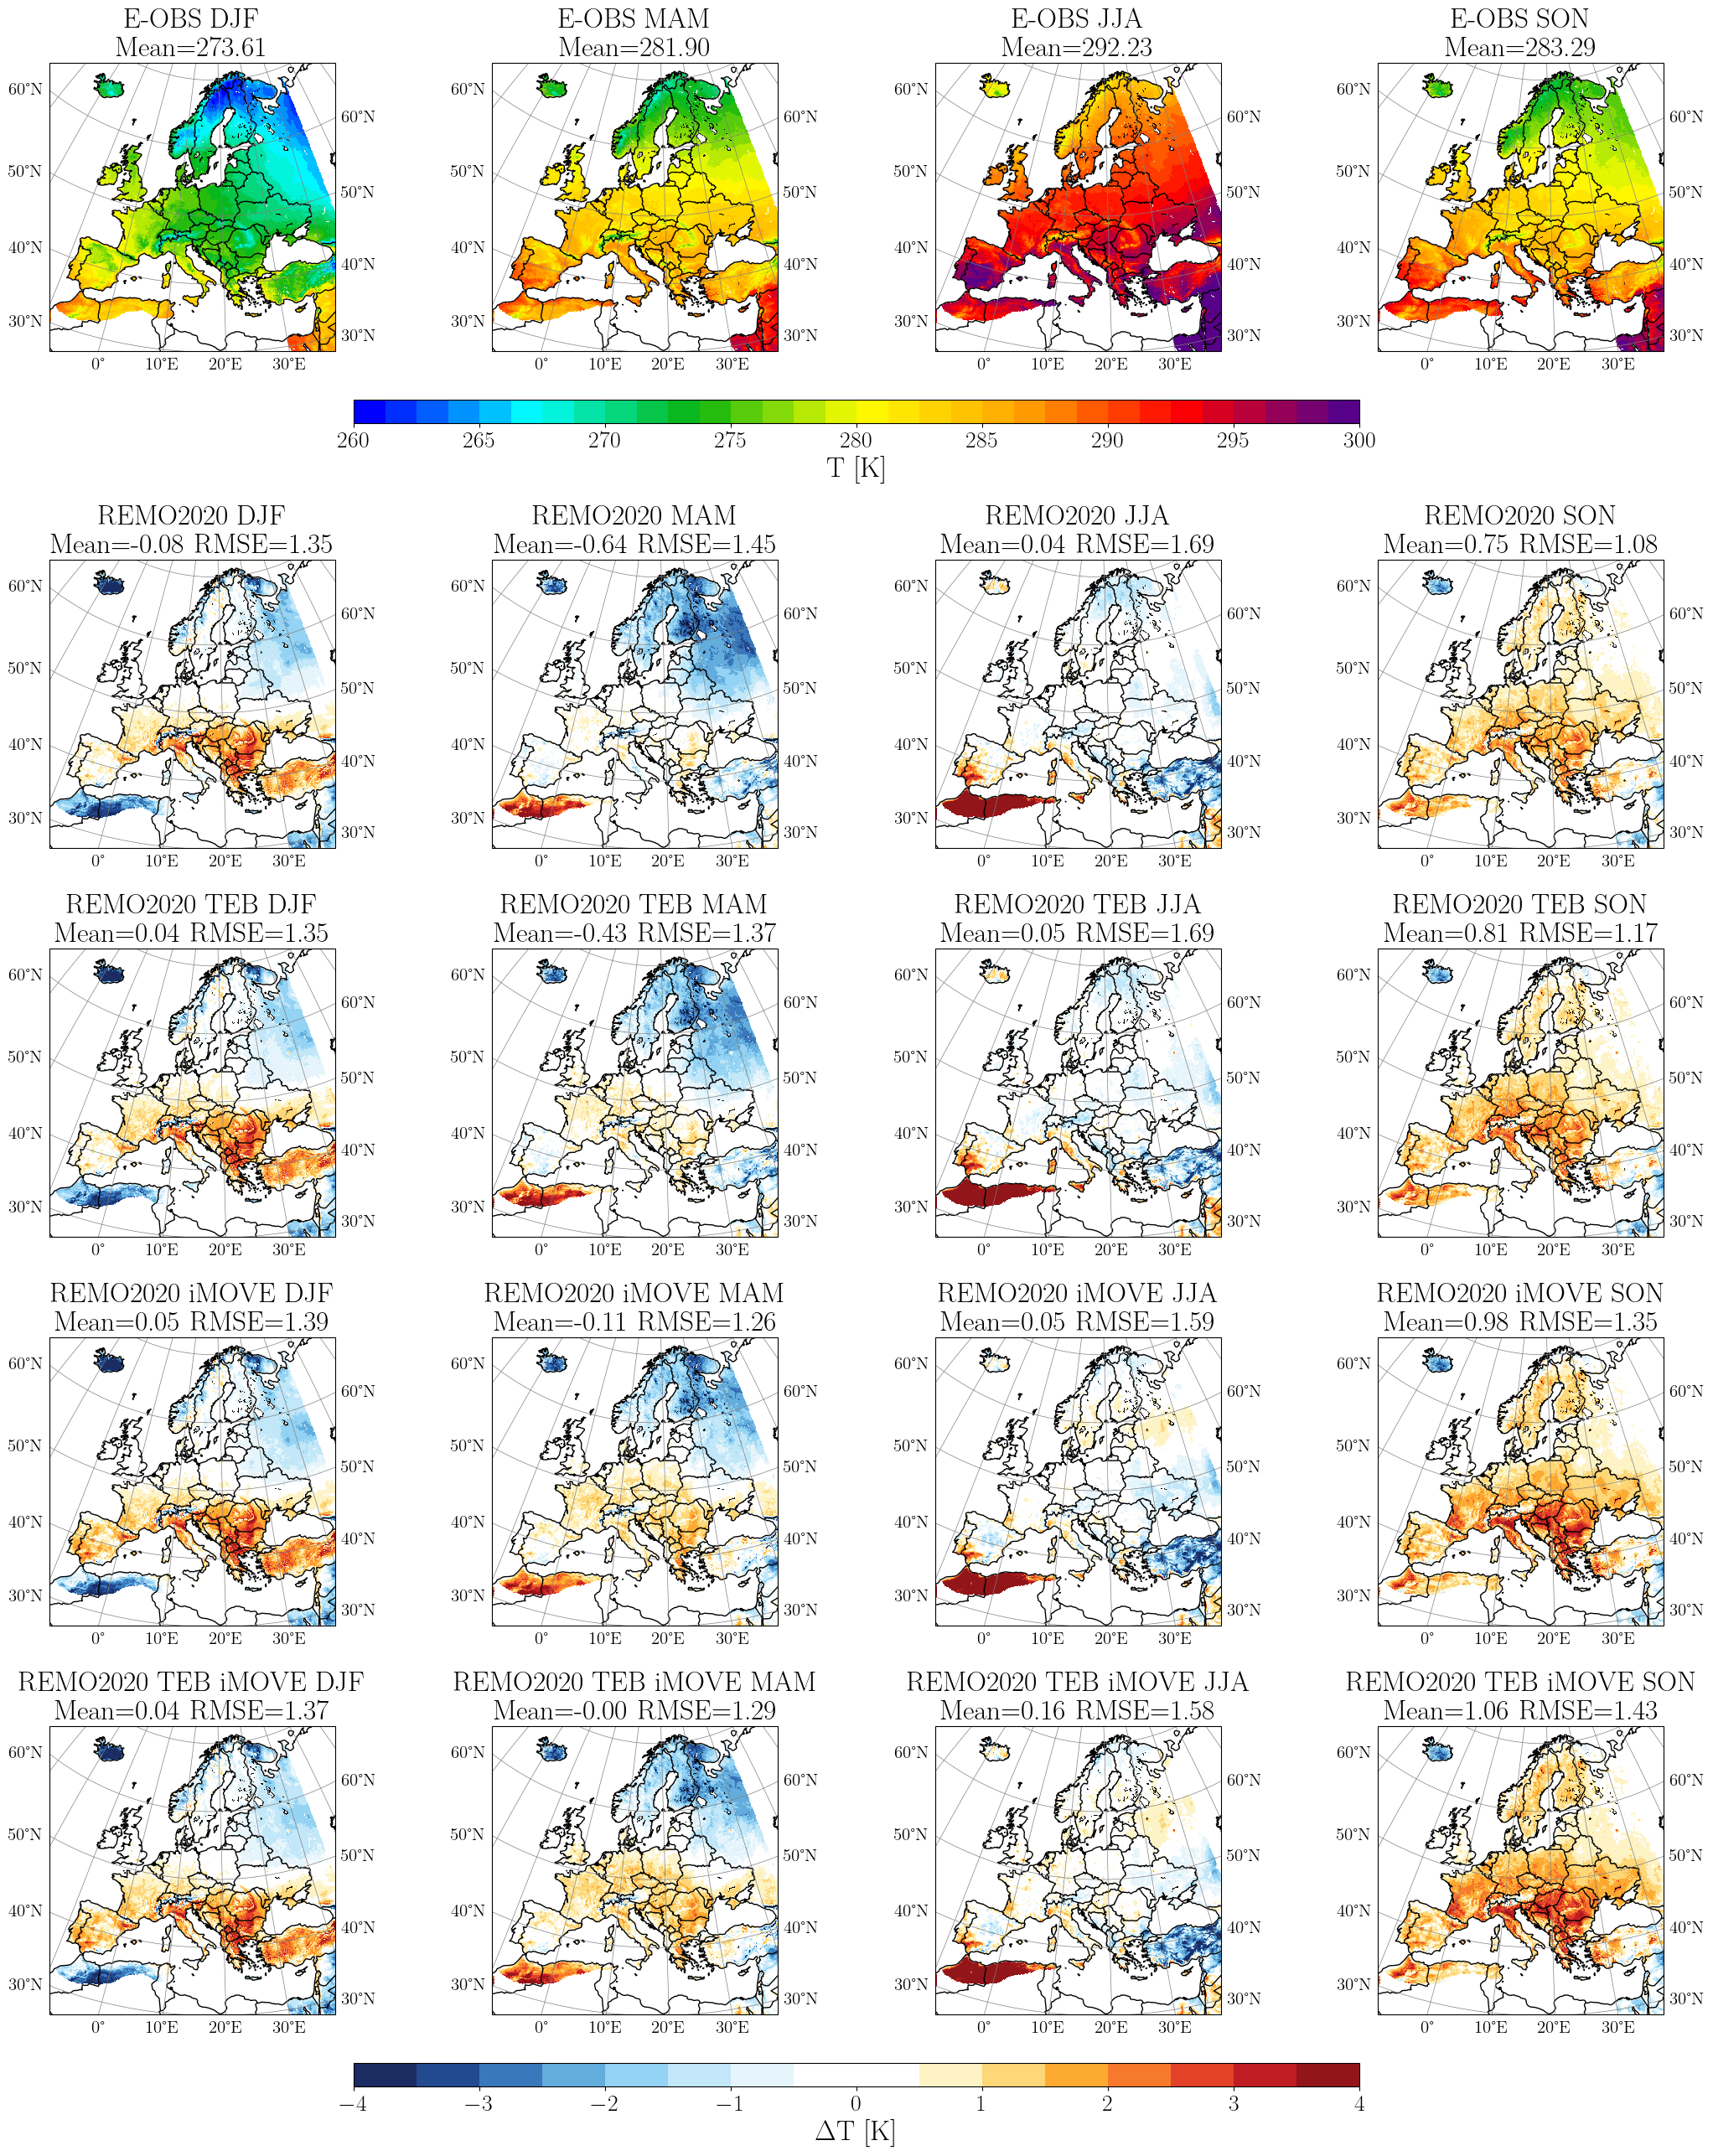

In [23]:
# Loop over domains
for dom in range(len(domaininfo)):
    # Create figure name
    figname=prefix+domaininfo[dom].name+'_'+suffix
    # Call plotter
    remo_plotter(absplotc,modplotc,domaininfo[dom],modelruns,"E-OBS",abs_vals_mean,seasons,pole,False,figpath,figname)